# Rectified flow

$$
(Z_0,Z_1)=\left(Z_0,\Phi_\theta(Z_0)\right),\qquad Z_0\sim\mathcal N(0,I).
$$
$$
Z_t=(1-t)Z_0+tZ_1,\qquad
\mathcal L_{\mathrm{reflow}}(\phi)=
\mathbb E\left[\frac{\|v_\phi(Z_T,T)-(Z_1-Z_0)\|^2}{3072}\right].
$$

[Paper](https://arxiv.org/abs/2209.03003) · [U-Net](../model/model.py)

In [1]:
import sys
from functools import partial
from time import perf_counter
import numpy as np
import jax
import jax.numpy as jnp
from datasets import load_dataset

sys.path.insert(0, "..")
from model.model import init_model, model_apply


data = load_dataset("uoft-cs/cifar10")
X_train = np.stack([np.asarray(image) for image in data["train"]["img"]])
X_train = X_train.astype(np.float32) / 127.5 - 1
split = np.random.default_rng(2).permutation(len(X_train))
train_images = X_train[split[1024:]]
val1 = X_train[split[:1024]]
val0 = np.asarray(jax.random.normal(jax.random.key(2), val1.shape))

batch_size = 128
lr = 2e-4
patience = 5
min_delta = 1e-3

## Velocity regression

$$
x_t=(1-t)x_0+tx_1,\qquad u=x_1-x_0,\qquad t\sim U[0,1].
$$

In [2]:
def make_flow_batch(x0, x1, key):
    t = jax.random.uniform(key, (len(x1), 1, 1, 1))
    return (1 - t) * x0 + t * x1, t, x1 - x0


def loss_fn(params, xt, t, target):
    return jnp.mean((model_apply(params, xt, t) - target)**2)


@jax.jit
def train_step(params, m, v, x0, x1, key, step):
    xt, t, target = make_flow_batch(x0, x1, key)
    loss, grads = jax.value_and_grad(loss_fn)(params, xt, t, target)
    m = jax.tree_util.tree_map(lambda a, g: 0.9 * a + 0.1 * g, m, grads)
    v = jax.tree_util.tree_map(lambda a, g: 0.999 * a + 0.001 * g**2, v, grads)
    params = jax.tree_util.tree_map(
        lambda p, a, b: p - lr * (a / (1 - 0.9**step))
        / (jnp.sqrt(b / (1 - 0.999**step)) + 1e-8), params, m, v
    )
    return params, m, v, loss


eval_loss = jax.jit(loss_fn)

## Training

In [3]:
def fit(params, images, validation, starts=None, epochs=50,
        batches=None, stop_early=True, seed=1):
    timer = perf_counter()
    key = jax.random.key(seed)
    rng = np.random.default_rng(seed)
    m = jax.tree_util.tree_map(jnp.zeros_like, params)
    v = jax.tree_util.tree_map(jnp.zeros_like, params)
    batches = len(images) // batch_size if batches is None else batches
    assert 0 < batches * batch_size <= len(images)
    assert starts is None or len(starts) == len(images)
    va, vb = (jnp.asarray(x) for x in validation)
    val_xt, val_t, val_target = make_flow_batch(va, vb, jax.random.key(1234))

    def validation_loss(p):
        return np.mean([
            float(eval_loss(p, val_xt[i:i + batch_size],
                            val_t[i:i + batch_size], val_target[i:i + batch_size]))
            for i in range(0, len(vb), batch_size)
        ])

    history = {"train": [], "val": [float(validation_loss(params))], "best_epoch": 0}
    best_loss = patience_loss = history["val"][0]
    if not np.isfinite(best_loss):
        raise FloatingPointError("Non-finite initial validation loss.")
    best_params = params
    step, stale = 0, 0
    for epoch in range(epochs):
        order = rng.permutation(len(images))
        total = 0.0
        for i in range(batches):
            indices = order[i * batch_size:(i + 1) * batch_size]
            x1 = jnp.asarray(images[indices])
            key, noise_key, time_key = jax.random.split(key, 3)
            x0 = (jax.random.normal(noise_key, x1.shape) if starts is None
                  else jnp.asarray(starts[indices]))
            step += 1
            params, m, v, loss = train_step(params, m, v, x0, x1, time_key, step)
            total += loss

        history["train"].append(float(total / batches))
        current = float(validation_loss(params))
        history["val"].append(current)
        print(f"{epoch + 1:3d} | train {history['train'][-1]:.5f} | val {current:.5f}")
        if not np.isfinite(history["train"][-1]) or not np.isfinite(current):
            raise FloatingPointError("Non-finite training or validation loss.")
        if current < best_loss:
            best_loss, best_params = current, params
            history["best_epoch"] = epoch + 1
        if current < patience_loss - min_delta:
            patience_loss, stale = current, 0
        else:
            stale += 1
        if stop_early and stale >= patience:
            break

    history["updates"] = step
    history["seconds"] = perf_counter() - timer
    print(f"Selected epoch {history['best_epoch']} | val {best_loss:.5f}")
    return best_params, history

## 1-RF: independent pairs

$$x_0\sim\mathcal N(0,I),\qquad x_1\sim p_{\mathrm{data}},\qquad x_0\perp x_1.$$

In [4]:
initial = init_model(jax.random.key(0))
teacher, teacher_history = fit(initial, train_images, (val0, val1), seed=1)
del initial

  1 | train 0.48738 | val 0.29673


  2 | train 0.27167 | val 0.26701


  3 | train 0.24815 | val 0.24591


  4 | train 0.23592 | val 0.23660


  5 | train 0.22785 | val 0.23223


  6 | train 0.22225 | val 0.22467


... (26 outputs left out)

 33 | train 0.18920 | val 0.19277


 34 | train 0.18907 | val 0.19204


 35 | train 0.18960 | val 0.19199


 36 | train 0.18842 | val 0.19228
Selected epoch 35 | val 0.19199


## Integration

$$
x_{k+1}^{\mathrm{Euler}}=x_k+h\,v_\theta(x_k,t_k),
$$
$$
a=v_\theta(x_k,t_k),\qquad b=v_\theta(x_k+ha,t_k+h),\qquad
x_{k+1}^{\mathrm{Heun}}=x_k+\tfrac h2(a+b).
$$

In [5]:
@partial(jax.jit, static_argnames=("steps",))
def euler(params, noise, steps=64):
    def advance(k, x):
        t = jnp.full((len(x), 1, 1, 1), k / steps)
        return x + model_apply(params, x, t) / steps
    return jax.lax.fori_loop(0, steps, advance, noise)


@partial(jax.jit, static_argnames=("steps",))
def heun(params, noise, steps=128):
    h = 1 / steps
    def advance(k, x):
        t = jnp.full((len(x), 1, 1, 1), k * h)
        a = model_apply(params, x, t)
        b = model_apply(params, x + h * a, t + h)
        return x + 0.5 * h * (a + b)
    return jax.lax.fori_loop(0, steps, advance, noise)

## Teacher pairs

$$z_0\sim\mathcal N(0,I),\qquad z_1=\Phi_\theta(z_0).$$

In [6]:
pair_count = 8192
teacher_steps = 128
pair_noise = np.asarray(jax.random.normal(jax.random.key(10), (pair_count, 32, 32, 3)))
reflow_val0 = np.asarray(jax.random.normal(jax.random.key(11), (1024, 32, 32, 3)))
pair_images = np.empty_like(pair_noise)
reflow_val1 = np.empty_like(reflow_val0)

timer = perf_counter()
for starts, endpoints in [(pair_noise, pair_images), (reflow_val0, reflow_val1)]:
    for i in range(0, len(starts), 64):
        endpoints[i:i + 64] = np.asarray(
            heun(teacher, jnp.asarray(starts[i:i + 64]), steps=teacher_steps)
        )
pair_seconds = perf_counter() - timer
assert np.isfinite(pair_images).all() and np.isfinite(reflow_val1).all()

## Reflow: 2-RF

$$\phi\leftarrow\theta,\qquad (x_0,x_1)\leftarrow(z_0,z_1).$$

In [7]:
student, reflow_history = fit(
    teacher, pair_images, (reflow_val0, reflow_val1),
    starts=pair_noise, epochs=30, seed=4
)

  1 | train 0.01392 | val 0.00654


  2 | train 0.00526 | val 0.00469


  3 | train 0.00406 | val 0.00409


  4 | train 0.00369 | val 0.00366


  5 | train 0.00347 | val 0.00339


  6 | train 0.00309 | val 0.00324


  7 | train 0.00302 | val 0.00310


  8 | train 0.00291 | val 0.00303


  9 | train 0.00286 | val 0.00285
Selected epoch 9 | val 0.00285


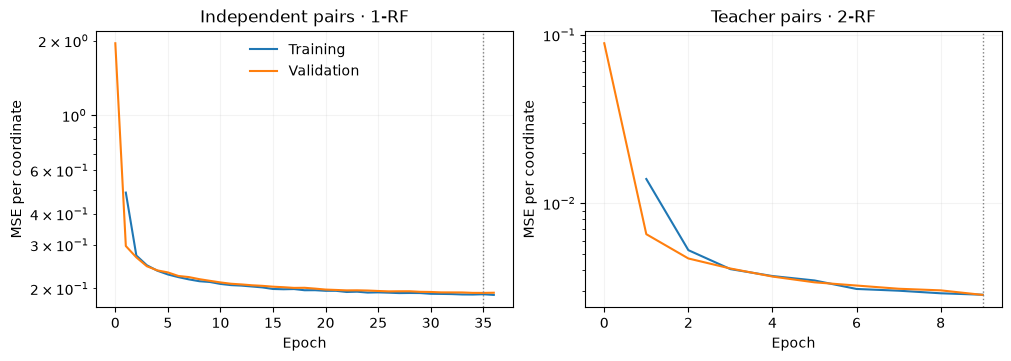

In [8]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for ax, history, title in zip(
    axes, [teacher_history, reflow_history], ["Independent pairs · 1-RF", "Teacher pairs · 2-RF"]
):
    ax.plot(np.arange(1, len(history["train"]) + 1), history["train"], label="Training")
    ax.plot(np.arange(len(history["val"])), history["val"], label="Validation")
    ax.axvline(history["best_epoch"], color="0.5", ls=":", lw=1)
    ax.set(title=title, xlabel="Epoch", ylabel="MSE per coordinate", yscale="log")
    ax.grid(alpha=0.15)
axes[0].legend(frameon=False)
plt.show()

## Generation

$$x_1^{\mathrm{1\ step}}=x_0+v_\phi(x_0,0).$$

In [9]:
preview_noise = jax.random.normal(jax.random.key(20), (4, 32, 32, 3))
preview_images = [
    np.asarray(euler(teacher, preview_noise, steps=1)),
    np.asarray(euler(teacher, preview_noise, steps=64)),
    np.asarray(euler(student, preview_noise, steps=1)),
]

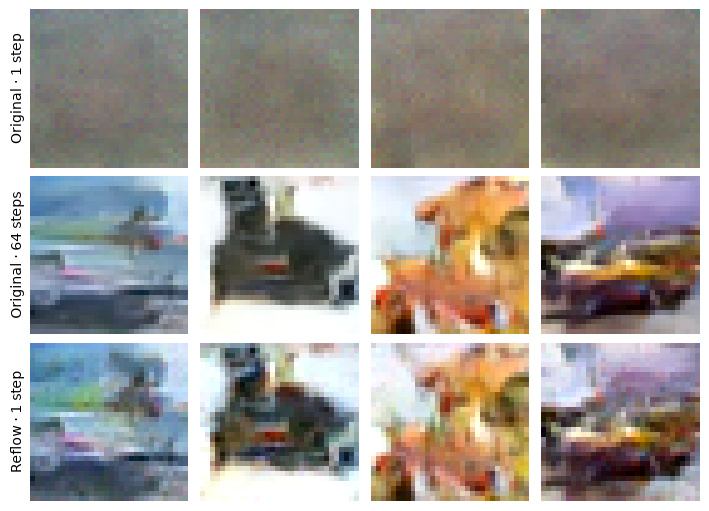

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(7, 5), layout="constrained")
for row, label in enumerate(["Original · 1 step", "Original · 64 steps", "Reflow · 1 step"]):
    for col in range(4):
        ax = axes[row, col]
        ax.imshow(np.clip((preview_images[row][col] + 1) / 2, 0, 1),
                  interpolation="nearest")
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if col == 0:
            ax.set_ylabel(label)
plt.show()